# Black-box surrogate for the heat benchmark — the extrapolation cliff

Learn the temperature field directly from **solver data**, with no equation. We run the
Chapter-1 finite-difference heat solver on a unit square (hot left/right edges, cold
top/bottom) for a range of thermal diffusivities $\alpha$, sample the field at a fixed time
$t^*$, and train an MLP
$$\hat T_\theta(x,y,\alpha)\approx T(x,y,t^*;\alpha).$$
Inside the training band of $\alpha$ the surrogate is excellent; **outside it the error explodes**
— the black box has no governing equation to carry it. This is exactly the gap the CoSTA hybrid
closes by keeping the physics and learning only the correction.

**The ground truth.** The benchmark solves the source-free 2-D heat equation
$$ \frac{\partial T}{\partial t} = \alpha\,\nabla^2 T $$
by explicit FTCS (central differences in space, forward Euler in time) on a $41\times41$ grid:
$$ T^{n+1}_{i,j} = T^{n}_{i,j} + \alpha\,\Delta t\left[
   \frac{T_{i+1,j}-2T_{i,j}+T_{i-1,j}}{\Delta x^2}
 + \frac{T_{i,j+1}-2T_{i,j}+T_{i,j-1}}{\Delta y^2}\right]. $$
**BC (Dirichlet):** hot left and right edges $T=1$, cold top and bottom edges $T=0$.
**IC:** $T\equiv 0$ in the interior. **Evaluation time:** $t^*=800\ \mathrm{s}$ (still transient).
**Swept parameter:** the thermal diffusivity $\alpha$, trained on the band
$\alpha\in\{3,4,5,6,7,8\}\times10^{-5}$; we later test a held-out **interpolation** value
$\alpha=6.5\times10^{-5}$ (inside the band) against an **extrapolation** value
$\alpha=1.7\times10^{-4}$ (far outside).

trained on alpha in [3.0e-05, 8.0e-05], 6 values


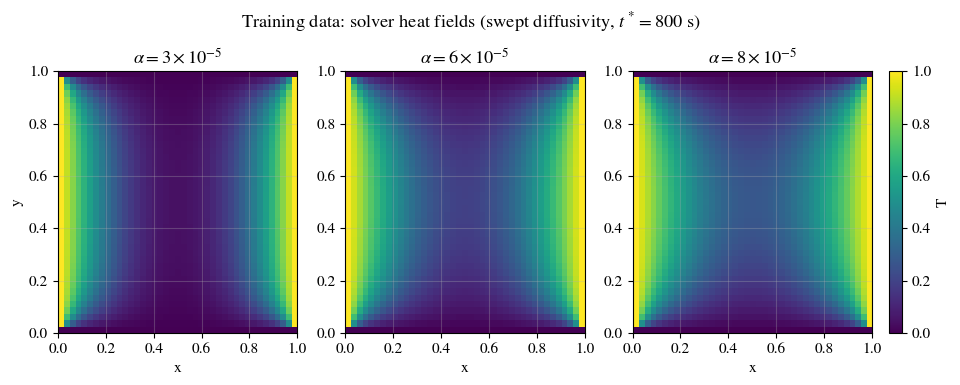

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..','..')))
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.pinn_core import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks.heat import HeatProblem, solve
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..','figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: the real 2-D heat solver, parametrized by diffusivity alpha
NX = 41; TSTAR = 800.0                       # evaluation time (transient regime)
x = np.linspace(0, 1, NX); y = np.linspace(0, 1, NX)
Xg, Yg = np.meshgrid(x, y, indexing='ij')

def field(a):
    "Solver temperature field T(x, y; alpha=a) at t = TSTAR."
    _, _, T = solve(HeatProblem(nx=NX, ny=NX, alpha=float(a)), t_end=TSTAR)
    return T

a_train = np.array([3, 4, 5, 6, 7, 8]) * 1e-5     # training diffusivities (the band)
A_LO, A_HI = float(a_train.min()), float(a_train.max())
fields_train = {float(a): field(a) for a in a_train}
print('trained on alpha in [%.1e, %.1e], %d values' % (A_LO, A_HI, len(a_train)))

# show the parametric training data: solver fields at low / mid / high alpha
def plot_ddm_heat_data():
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    show_a = [a_train[0], a_train[len(a_train)//2], a_train[-1]]
    for j, a in enumerate(show_a):
        im = ax[j].imshow(fields_train[float(a)].T, origin='lower', extent=[0, 1, 0, 1],
                          vmin=0, vmax=1, cmap='viridis', aspect='auto')
        ax[j].set(title=f'$\\alpha = {a*1e5:.0f}\\times10^{{-5}}$',
                  xlabel='x', ylabel='y' if j == 0 else '')
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label='T')
    fig.suptitle(f'Training data: solver heat fields (swept diffusivity, $t^*={TSTAR:.0f}$ s)',
                 y=1.06)

save_dual(plot_ddm_heat_data, 'ddm_heat_data', FIG); plt.show()

The print confirms the training budget: **six solver runs**, one per diffusivity across the band
$[3,8]\times10^{-5}$. The figure shows three of them ($\alpha = 3,6,8\times10^{-5}$): every panel
has the same hot left/right edges ($T=1$) and cold top/bottom edges ($T=0$), but $\alpha$ controls
how far that boundary heat has soaked inward by $t^*=800\ \mathrm{s}$. At $\alpha=3\times10^{-5}$
the interior is still mostly cold — a narrow warm collar hugs the side walls — whereas at
$\alpha=8\times10^{-5}$ the warm front has pushed well toward the centre. This genuine variation
across the band is what makes interpolation non-trivial, and it leaves `fields_train` holding the
six ground-truth fields the surrogate is fit to.

## Train the surrogate, then sweep $\alpha$: the cliff

The MLP maps $(x,y,\alpha)\to T$ and is trained **only** on the diffusivity band. Architecture
`MLP([3, 96, 96, 96, 1])` (three hidden layers of 96 units); the inputs $(x,y,\alpha)$ and the
target $T$ are standardized, and we minimize the mean-squared error
$$ \mathcal L(\theta)=\frac1N\sum_{i}\big(\hat T_\theta(x_i,y_i,\alpha_i)-T_i\big)^2 $$
over all $6\times41\times41$ grid samples with 8000 Adam steps (`lr=2e-3`). We then sweep $\alpha$
across `linspace(1e-5, 1.8e-4, 40)` — from well below to well above the band — and measure the
field RMSE against the solver at each value. Finally we compare centerline profiles ($T$ at
$y=0.5$) at the held-out **interpolation** $\alpha=6.5\times10^{-5}$ and the **extrapolation**
$\alpha=1.7\times10^{-4}$. Inside the band the error is tiny; outside it, it climbs sharply.

final train loss 1.95e-05


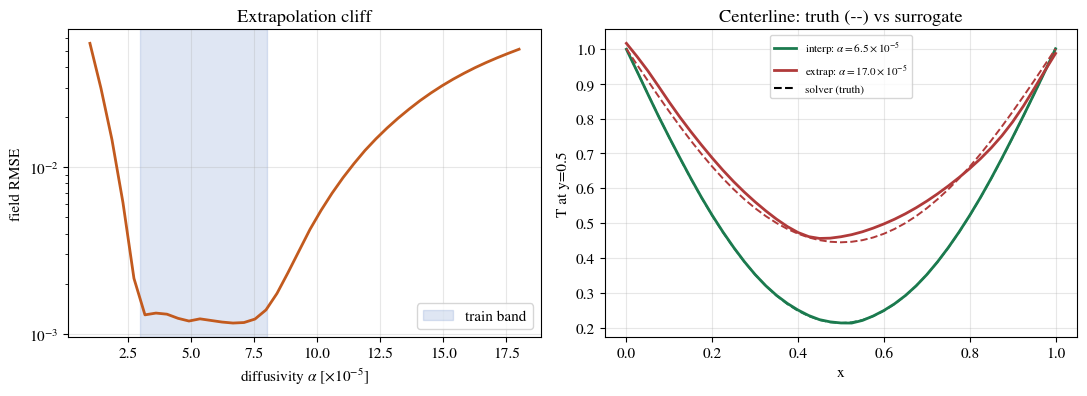

field RMSE  in-band=1.246e-03   extrap-low=5.539e-02   extrap-high=5.108e-02
extrapolation error is 41x (high) / 44x (low) the in-band error


In [2]:
# --- surrogate: MLP (x, y, alpha) -> T, trained ONLY on the alpha band --------
Xtr, Ytr = [], []
for a in a_train:
    T = fields_train[float(a)]
    for i in range(NX):
        for j in range(NX):
            Xtr.append([x[i], y[j], float(a)]); Ytr.append(T[i, j])
Xtr = np.array(Xtr); Ytr = np.array(Ytr).reshape(-1, 1)
Xm, Xs = Xtr.mean(0), Xtr.std(0); Ym, Ys = Ytr.mean(), Ytr.std()
Xt = torch.tensor((Xtr - Xm) / Xs); Yt = torch.tensor((Ytr - Ym) / Ys)

torch.manual_seed(0); net = MLP([3, 96, 96, 96, 1])
opt = torch.optim.Adam(net.parameters(), lr=2e-3)
for ep in range(8000):
    opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
print('final train loss %.2e' % float(loss.detach()))

def predict_field(a):
    P = np.c_[Xg.ravel(), Yg.ravel(), np.full(Xg.size, float(a))]
    with torch.no_grad():
        out = net(torch.tensor((P - Xm) / Xs)).numpy().ravel() * Ys + Ym
    return out.reshape(NX, NX)

# --- sweep alpha across and beyond the band: the extrapolation cliff -----------
a_sweep = np.linspace(1e-5, 1.8e-4, 40)
rmse = np.array([np.sqrt(np.mean((predict_field(a) - field(a))**2)) for a in a_sweep])
inband = (a_sweep >= A_LO) & (a_sweep <= A_HI)
a_interp, a_extrap = 6.5e-5, 1.7e-4           # held-out inside / outside the band

def plot_ddm_heat_cliff():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.1))
    ax[0].axvspan(A_LO*1e5, A_HI*1e5, color='C0', alpha=0.15, label='train band')
    ax[0].semilogy(a_sweep*1e5, rmse, 'C1', lw=2)
    ax[0].set(xlabel='diffusivity $\\alpha$ $[\\times10^{-5}]$', ylabel='field RMSE',
              title='Extrapolation cliff'); ax[0].legend()
    mid = NX // 2
    for a, c, tag in [(a_interp, 'C2', 'interp'), (a_extrap, 'C3', 'extrap')]:
        Tt = field(a); Tp = predict_field(a)
        ax[1].plot(x, Tt[:, mid], '--', color=c, lw=1.4)
        ax[1].plot(x, Tp[:, mid], color=c, lw=2,
                   label=f'{tag}: $\\alpha={a*1e5:.1f}\\times10^{{-5}}$')
    ax[1].plot([], [], '--', color=fg(), label='solver (truth)')
    ax[1].set(xlabel='x', ylabel='T at y=0.5',
              title='Centerline: truth (--) vs surrogate'); ax[1].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_ddm_heat_cliff, 'ddm_heat_cliff', FIG); plt.show()
r_in, r_lo, r_hi = rmse[inband].mean(), rmse[0], rmse[-1]
print(f'field RMSE  in-band={r_in:.3e}   extrap-low={r_lo:.3e}   extrap-high={r_hi:.3e}')
print(f'extrapolation error is {r_hi/r_in:.0f}x (high) / {r_lo/r_in:.0f}x (low) the in-band error')
assert r_hi > 8*r_in and r_lo > 8*r_in       # error explodes outside the band

The surrogate fits its training data almost perfectly (final train loss $1.95\times10^{-5}$), and
the numbers make the cliff quantitative: field RMSE $\approx1.25\times10^{-3}$ **in-band** versus
$5.1\times10^{-2}$ (high side) and $5.5\times10^{-2}$ (low side) — a **$41\times$–$44\times$** jump
the moment $\alpha$ leaves the training range, so the `assert` that extrapolation error exceeds
$8\times$ the in-band error passes easily. The left panel draws this as a **U-shaped cliff**: RMSE
is flat and near $10^{-3}$ across the shaded train band, then rises steeply on both sides. The right
panel makes it physical — the green **interpolation** centerline ($\alpha=6.5\times10^{-5}$) lies
right on the dashed solver truth, while the red **extrapolation** curve ($\alpha=17\times10^{-5}$)
visibly pulls off its own truth near the centre. Interpolating a diffusivity between training
values is safe; asking for one outside the band is not.

**Lesson.** The surrogate is fast and accurate *inside* its training distribution of $\alpha$ but
has no mechanism to extrapolate — the field it predicts for an unseen diffusivity drifts away from
the solver. There is no conservation law or governing equation to anchor it. This is exactly the
gap that physics-informed and hybrid (CoSTA) methods fill: keep the trusted heat equation and let
the network supply only the missing/uncertain part, so accuracy survives outside the training set.
A calibrated uncertainty estimate (the uncertainty notebook) would at least flag the unreliable
region before you trust it.